# Exploratory Data Analysis and Insights on Online Shopping Sessions Using Pandas

### Beginner-to-Intermediate Pandas Practice Notebook

This notebook is designed for students who are learning how to explore website-session and e-commerce data using **Pandas**.

The exercises begin with basic DataFrame operations and gradually introduce:

- Loading and inspecting a CSV file
- Checking missing and duplicate values
- Exploring numerical, categorical, and Boolean columns
- Selecting, filtering, and sorting sessions
- Grouping and aggregating visitor behavior
- Creating engagement measures
- Examining correlations
- Creating basic visualizations
- Exporting an analyzed DataFrame


## About the Dataset

The **OnlineShoppers.csv** dataset contains **12,330 online shopping sessions** collected over one year. Each row represents a different user session.

It contains **18 columns**:

| Group | Example columns | Description |
|---|---|---|
| Page activity | `administrative_pages`, `informational_pages`, `product_related_pages` | Number of pages visited in each category |
| Visit duration | `administrative_duration`, `informational_duration`, `product_related_duration` | Time spent in each page category |
| Web metrics | `bounce_rate`, `exit_rate`, `page_value`, `special_day` | Session and page-performance measurements |
| Technical details | `operating_system`, `browser`, `region`, `traffic_type` | Encoded technical and traffic-source categories |
| Visitor details | `month`, `visitor_type`, `weekend` | Timing and visitor classification |
| Outcome | `revenue` | Boolean value indicating whether the session ended with a purchase |

### Important Observation

The `weekend` and `revenue` columns contain Boolean values. `True` means the condition occurred, while `False` means it did not. Most sessions do not end with a purchase, so the outcome classes are not evenly balanced.

The original column names were converted to descriptive snake_case names. The session records were not otherwise changed.

**Source:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset)  
**License:** CC BY 4.0


## Learning Goal

By completing this assignment, you will practice a complete beginner-to-intermediate Pandas workflow. You will compare purchasing and non-purchasing sessions, explore visitor behavior, create engagement measures, and summarize relationships between activity and revenue.


## 1. Loading and Understanding the Dataset

### Question 1
Import the Pandas library using the alias `pd` and read **OnlineShoppers.csv** into a DataFrame named `df`.


In [2]:
import pandas as pd
path = "C:\\Users\\Tasmiya\\Desktop\\Assignments\\Assignment No 12\\OnlineShoppers.csv"
df = pd.read_csv(path)
df

,administrative_pages,administrative_duration,informational_pages,informational_duration,product_related_pages,product_related_duration,bounce_rate,exit_rate,page_value,special_day,month,operating_system,browser,region,traffic_type,visitor_type,weekend,revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False


### Question 2
Display the first **5 rows** of the dataset.


In [2]:
df.head(5)

,administrative_pages,administrative_duration,informational_pages,informational_duration,product_related_pages,product_related_duration,bounce_rate,exit_rate,page_value,special_day,month,operating_system,browser,region,traffic_type,visitor_type,weekend,revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


### Question 3
Display the last **5 rows** of the dataset.


In [3]:
df.tail(5)

,administrative_pages,administrative_duration,informational_pages,informational_duration,product_related_pages,product_related_duration,bounce_rate,exit_rate,page_value,special_day,month,operating_system,browser,region,traffic_type,visitor_type,weekend,revenue
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False
12329,0,0.0,0,0.0,3,21.250000,0.000000,0.066667,0.000000,0.0,Nov,3,2,1,2,New_Visitor,True,False


### Question 4
Find the total number of **rows and columns** in the dataset.


In [4]:
df.shape

(12330, 18)

### Question 5
Display all the **column names** in the dataset.


In [6]:
df.columns

Index(['administrative_pages', 'administrative_duration',
       'informational_pages', 'informational_duration',
       'product_related_pages', 'product_related_duration', 'bounce_rate',
       'exit_rate', 'page_value', 'special_day', 'month', 'operating_system',
       'browser', 'region', 'traffic_type', 'visitor_type', 'weekend',
       'revenue'],
      dtype='object')

### Question 6
Display the **data type of each column**.


In [8]:
df.dtypes

administrative_pages          int64
administrative_duration     float64
informational_pages           int64
informational_duration      float64
product_related_pages         int64
product_related_duration    float64
bounce_rate                 float64
exit_rate                   float64
page_value                  float64
special_day                 float64
month                        object
operating_system              int64
browser                       int64
region                        int64
traffic_type                  int64
visitor_type                 object
weekend                        bool
revenue                        bool
dtype: object

### Question 7
Display a complete summary of the DataFrame using `info()`.


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   administrative_pages      12330 non-null  int64  
 1   administrative_duration   12330 non-null  float64
 2   informational_pages       12330 non-null  int64  
 3   informational_duration    12330 non-null  float64
 4   product_related_pages     12330 non-null  int64  
 5   product_related_duration  12330 non-null  float64
 6   bounce_rate               12330 non-null  float64
 7   exit_rate                 12330 non-null  float64
 8   page_value                12330 non-null  float64
 9   special_day               12330 non-null  float64
 10  month                     12330 non-null  object 
 11  operating_system          12330 non-null  int64  
 12  browser                   12330 non-null  int64  
 13  region                    12330 non-null  int64  
 14  traffi

## 2. Checking Data Quality

### Question 8
Display the number of **missing values in each column**.


In [10]:
df.isnull().sum()

administrative_pages        0
administrative_duration     0
informational_pages         0
informational_duration      0
product_related_pages       0
product_related_duration    0
bounce_rate                 0
exit_rate                   0
page_value                  0
special_day                 0
month                       0
operating_system            0
browser                     0
region                      0
traffic_type                0
visitor_type                0
weekend                     0
revenue                     0
dtype: int64

### Question 9
Calculate the **total number of missing values** in the entire DataFrame.


In [11]:
df.isnull().sum().sum()

np.int64(0)

### Question 10
Check the number of **duplicate rows** in the dataset.


In [12]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
12325    False
12326    False
12327    False
12328    False
12329    False
Length: 12330, dtype: bool

### Question 11
Create a new DataFrame named `df_clean` using `df.drop_duplicates().copy()`, then display its shape.


In [14]:
df_clean = df.drop_duplicates().copy()
df_clean.shape

(12205, 18)

## 3. Selecting Rows and Columns

### Question 12
Select and display only the **revenue** column from `df_clean`.


In [16]:
df_clean['revenue']

0        False
1        False
2        False
3        False
4        False
         ...  
12325    False
12326    False
12327    False
12328    False
12329    False
Name: revenue, Length: 12205, dtype: bool

### Question 13
Select and display the **month, visitor_type, product_related_pages, page_value, weekend, and revenue** columns.


In [17]:
df[['month', 'visitor_type', 'product_related_pages', 'page_value', 'weekend', 'revenue']]

,month,visitor_type,product_related_pages,page_value,weekend,revenue
0,Feb,Returning_Visitor,1,0.000000,False,False
1,Feb,Returning_Visitor,2,0.000000,False,False
2,Feb,Returning_Visitor,1,0.000000,False,False
3,Feb,Returning_Visitor,2,0.000000,False,False
4,Feb,Returning_Visitor,10,0.000000,True,False
...,...,...,...,...,...,...
12325,Dec,Returning_Visitor,53,12.241717,True,False
12326,Nov,Returning_Visitor,5,0.000000,True,False
12327,Nov,Returning_Visitor,6,0.000000,True,False
12328,Nov,Returning_Visitor,15,0.000000,False,False


### Question 14
Display the first **10 rows** using DataFrame slicing.


In [18]:
df[:10]

,administrative_pages,administrative_duration,informational_pages,informational_duration,product_related_pages,product_related_duration,bounce_rate,exit_rate,page_value,special_day,month,operating_system,browser,region,traffic_type,visitor_type,weekend,revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
5,0,0.0,0,0.0,19,154.216667,0.015789,0.024561,0.0,0.0,Feb,2,2,1,3,Returning_Visitor,False,False
6,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.4,Feb,2,4,3,3,Returning_Visitor,False,False
7,1,0.0,0,0.0,0,0.000000,0.200000,0.200000,0.0,0.0,Feb,1,2,1,5,Returning_Visitor,True,False
8,0,0.0,0,0.0,2,37.000000,0.000000,0.100000,0.0,0.8,Feb,2,2,2,3,Returning_Visitor,False,False
9,0,0.0,0,0.0,3,738.000000,0.000000,0.022222,0.0,0.4,Feb,2,4,1,2,Returning_Visitor,False,False


### Question 15
Using `iloc`, display the first **5 rows and first 6 columns**.


In [19]:
df.iloc[0:5, 0:6]

,administrative_pages,administrative_duration,informational_pages,informational_duration,product_related_pages,product_related_duration
0,0,0.0,0,0.0,1,0.000000
1,0,0.0,0,0.0,2,64.000000
2,0,0.0,0,0.0,1,0.000000
3,0,0.0,0,0.0,2,2.666667
4,0,0.0,0,0.0,10,627.500000


### Question 16
Using `loc`, display rows **10 to 15** for the columns **product_related_pages, product_related_duration, bounce_rate, page_value, and revenue**.


In [26]:
df.loc[10:15, ['product_related_pages', 'product_related_duration', 'bounce_rate', 'page_value','revenue']]

,product_related_pages,product_related_duration,bounce_rate,page_value,revenue
10,3,395.000000,0.000000,0.0,False
11,16,407.750000,0.018750,0.0,False
12,7,280.500000,0.000000,0.0,False
13,6,98.000000,0.000000,0.0,False
14,2,68.000000,0.000000,0.0,False
15,23,1668.285119,0.008333,0.0,False


## 4. Categories and Descriptive Statistics

### Question 17
Count the `True` and `False` values in the **revenue** column.


In [27]:
df['revenue'].value_counts()

revenue
False    10422
True      1908
Name: count, dtype: int64

### Question 18
Count the sessions for each **visitor_type**.


In [28]:
df['visitor_type'].value_counts()

visitor_type
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64

### Question 19
Count the number of sessions recorded in each **month**.


In [29]:
df['month'].value_counts()

month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64

### Question 20
Count the `True` and `False` values in the **weekend** column.


In [30]:
df['weekend'].value_counts()

weekend
False    9462
True     2868
Name: count, dtype: int64

### Question 21
Display descriptive statistics for the numeric columns using `describe()`.


In [31]:
df.describe()

,administrative_pages,administrative_duration,informational_pages,informational_duration,product_related_pages,product_related_duration,bounce_rate,exit_rate,page_value,special_day,operating_system,browser,region,traffic_type
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


### Question 22
Calculate the mean **product_related_pages** and mean **product_related_duration**.


In [32]:
df['product_related_pages'].mean() , df['product_related_duration'].mean()

(np.float64(31.731467964314678), np.float64(1194.7462199688268))

## 5. Filtering and Sorting

### Question 23
Display all sessions where **revenue is `True`**.


In [5]:
df[df['revenue'] == True]

,administrative_pages,administrative_duration,informational_pages,informational_duration,product_related_pages,product_related_duration,bounce_rate,exit_rate,page_value,special_day,month,operating_system,browser,region,traffic_type,visitor_type,weekend,revenue
65,3,87.833333,0,0.00,27,798.333333,0.000000,0.012644,22.916036,0.8,Feb,2,2,3,1,Returning_Visitor,False,True
76,10,1005.666667,0,0.00,36,2111.341667,0.004348,0.014493,11.439412,0.0,Feb,2,6,1,2,Returning_Visitor,False,True
101,4,61.000000,0,0.00,19,607.000000,0.000000,0.026984,17.535959,1.0,Feb,1,1,7,4,Returning_Visitor,True,True
188,9,111.500000,1,48.50,49,1868.819697,0.000000,0.020709,1.706015,0.0,Mar,2,2,7,2,Returning_Visitor,False,True
196,2,56.000000,1,144.00,67,2563.783333,0.000000,0.005797,19.342650,0.0,Mar,2,2,4,2,New_Visitor,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12272,6,133.466667,0,0.00,44,2664.445833,0.002041,0.010884,97.860836,0.0,Nov,2,2,1,3,Returning_Visitor,True,True
12276,7,139.575000,0,0.00,30,986.500000,0.000000,0.011429,36.392861,0.0,Dec,2,10,1,2,New_Visitor,False,True
12311,1,0.000000,2,211.25,144,4627.489571,0.001361,0.020664,0.000000,0.0,Nov,2,2,1,2,Returning_Visitor,False,True
12312,7,150.357143,1,9.00,221,11431.001240,0.011149,0.021904,1.582473,0.0,Nov,2,5,1,2,Returning_Visitor,True,True


### Question 24
Display sessions from **Returning_Visitor** users that occurred on a weekend.


In [10]:
df[(df['visitor_type'] == 'Returning_Visitor') & (df['weekend'] == True)]

,administrative_pages,administrative_duration,informational_pages,informational_duration,product_related_pages,product_related_duration,bounce_rate,exit_rate,page_value,special_day,month,operating_system,browser,region,traffic_type,visitor_type,weekend,revenue
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
7,1,0.0,0,0.0,0,0.000000,0.200000,0.200000,0.000000,0.0,Feb,1,2,1,5,Returning_Visitor,True,False
17,0,0.0,0,0.0,13,334.966667,0.000000,0.007692,0.000000,0.0,Feb,1,1,1,4,Returning_Visitor,True,False
20,0,0.0,0,0.0,8,136.166667,0.000000,0.008333,0.000000,1.0,Feb,2,2,5,1,Returning_Visitor,True,False
24,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Feb,2,2,4,1,Returning_Visitor,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12315,0,0.0,0,0.0,7,212.500000,0.000000,0.033333,0.000000,0.0,Nov,3,2,1,11,Returning_Visitor,True,False
12318,0,0.0,0,0.0,6,279.000000,0.000000,0.033333,0.000000,0.0,Dec,1,2,3,10,Returning_Visitor,True,False
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False


### Question 25
Display sessions where **page_value is greater than 50**.


In [11]:
df[df['page_value' ] > 50]

,administrative_pages,administrative_duration,informational_pages,informational_duration,product_related_pages,product_related_duration,bounce_rate,exit_rate,page_value,special_day,month,operating_system,browser,region,traffic_type,visitor_type,weekend,revenue
29,1,6.000000,1,0.0,45,1582.750000,0.043478,0.050821,54.179764,0.4,Feb,3,2,1,1,Returning_Visitor,False,False
198,0,0.000000,0,0.0,17,840.233333,0.000000,0.001667,109.176000,0.0,Mar,2,2,9,2,New_Visitor,False,True
199,3,94.000000,2,125.0,55,1970.844805,0.000000,0.001724,96.255116,0.0,Mar,2,4,1,2,New_Visitor,True,True
200,1,32.000000,0,0.0,50,2867.000000,0.000000,0.004000,153.443248,0.0,Mar,2,2,7,8,Returning_Visitor,True,True
265,0,0.000000,0,0.0,63,5220.083333,0.000000,0.003330,51.463311,0.0,Mar,2,5,3,1,Returning_Visitor,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12223,5,40.136364,0,0.0,35,840.995292,0.005263,0.012594,64.722389,0.0,Nov,2,2,1,1,Returning_Visitor,False,True
12234,0,0.000000,0,0.0,36,872.833333,0.000000,0.007059,81.027296,0.0,Nov,2,4,1,8,New_Visitor,False,True
12247,7,311.136111,0,0.0,36,1699.073611,0.010088,0.035614,133.281379,0.0,Dec,3,2,1,13,Returning_Visitor,False,False
12272,6,133.466667,0,0.0,44,2664.445833,0.002041,0.010884,97.860836,0.0,Nov,2,2,1,3,Returning_Visitor,True,True


### Question 26
Using `query()`, display sessions where **bounce_rate is below 0.02** and **product_related_pages is greater than 50**.


In [12]:
df.query('bounce_rate < 0.02 and product_related_pages > 50' )

,administrative_pages,administrative_duration,informational_pages,informational_duration,product_related_pages,product_related_duration,bounce_rate,exit_rate,page_value,special_day,month,operating_system,browser,region,traffic_type,visitor_type,weekend,revenue
35,0,0.000000,0,0.00,52,2086.242857,0.015385,0.020353,0.000000,0.0,Feb,2,2,7,1,Returning_Visitor,False,False
66,4,44.000000,0,0.00,90,6951.972222,0.002151,0.015013,0.000000,0.0,Feb,4,1,1,3,Returning_Visitor,False,False
109,6,326.250000,4,94.00,128,5062.213753,0.000855,0.017918,0.000000,0.0,Feb,2,5,1,3,Returning_Visitor,False,False
128,4,462.000000,0,0.00,51,1873.216667,0.000000,0.007547,0.000000,0.6,Feb,2,2,9,3,Returning_Visitor,False,False
187,10,293.778205,2,153.00,96,3283.166739,0.001961,0.013509,0.000000,0.0,Mar,3,2,6,2,Returning_Visitor,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12287,8,167.910714,6,547.75,111,6340.152381,0.003361,0.009432,44.219794,0.0,Dec,3,2,6,2,Returning_Visitor,False,False
12311,1,0.000000,2,211.25,144,4627.489571,0.001361,0.020664,0.000000,0.0,Nov,2,2,1,2,Returning_Visitor,False,True
12312,7,150.357143,1,9.00,221,11431.001240,0.011149,0.021904,1.582473,0.0,Nov,2,5,1,2,Returning_Visitor,True,True
12317,3,100.500000,0,0.00,95,1453.640882,0.002105,0.012761,0.000000,0.0,Dec,2,2,3,2,New_Visitor,False,False


### Question 27
Sort `df_clean` by **product_related_duration in descending order** and display the first 10 rows.


In [15]:
df_clean.sort_values(by='product_related_duration' , ascending= False).head(10)

,administrative_pages,administrative_duration,informational_pages,informational_duration,product_related_pages,product_related_duration,bounce_rate,exit_rate,page_value,special_day,month,operating_system,browser,region,traffic_type,visitor_type,weekend,revenue
8071,5,3398.750000,6,2549.375000,449,63973.52223,0.000764,0.027701,0.000000,0.0,Dec,2,2,1,2,Returning_Visitor,False,False
5152,17,2629.253968,24,2050.433333,705,43171.23338,0.004851,0.015431,0.763829,0.0,May,2,2,1,14,Returning_Visitor,True,False
9238,15,2657.318056,13,1949.166667,343,29970.46597,0.005316,0.028971,0.000000,0.0,Dec,2,2,1,2,Returning_Visitor,False,False
8784,20,1307.675000,3,132.666667,517,27009.85943,0.004385,0.014594,8.403164,0.0,Nov,1,1,1,2,Returning_Visitor,False,True
8308,27,853.735949,2,126.500000,584,24844.15620,0.002099,0.009347,4.511100,0.0,Nov,2,4,3,8,Returning_Visitor,False,False
7662,10,1251.200000,7,250.000000,414,23888.81000,0.009900,0.027062,1.033757,0.0,Sep,2,2,4,13,Returning_Visitor,False,False
6684,20,199.456273,7,299.033333,686,23342.08205,0.009853,0.022771,0.150650,0.0,Aug,2,2,1,1,Returning_Visitor,False,False
6165,10,2407.423810,3,434.300000,486,23050.10414,0.000324,0.011249,0.000000,0.0,Jul,2,2,1,3,Returning_Visitor,False,False
5916,12,245.733333,4,1511.700000,439,21857.04648,0.003589,0.012498,11.439233,0.0,Sep,2,2,1,13,Returning_Visitor,False,False
8972,11,631.416667,5,1037.150000,501,21672.24425,0.003965,0.014292,9.131387,0.0,Nov,2,2,1,2,Returning_Visitor,False,True


### Question 28
Display the **5 sessions with the highest page_value**.


In [16]:
df.nlargest(5,'page_value')

,administrative_pages,administrative_duration,informational_pages,informational_duration,product_related_pages,product_related_duration,bounce_rate,exit_rate,page_value,special_day,month,operating_system,browser,region,traffic_type,visitor_type,weekend,revenue
9239,3,37.5,0,0.0,18,607.500000,0.0,0.010526,361.763742,0.0,Nov,2,2,3,2,New_Visitor,False,True
8635,0,0.0,0,0.0,44,784.883333,0.0,0.004762,360.953384,0.0,Dec,8,13,9,20,Other,False,True
10853,0,0.0,0,0.0,12,366.500000,0.0,0.016667,287.953793,0.0,Dec,2,2,1,2,New_Visitor,False,True
11816,0,0.0,0,0.0,7,432.000000,0.0,0.014286,270.784693,0.0,Nov,2,4,1,8,New_Visitor,False,True
1491,5,172.2,0,0.0,23,792.722222,0.0,0.010714,261.491286,0.0,Mar,2,2,1,8,New_Visitor,False,True


## 6. Grouping and Aggregation

### Question 29
Calculate the **average page_value for each revenue outcome**.


In [17]:
df.groupby('revenue')['page_value'].mean()

revenue
False     1.975998
True     27.264518
Name: page_value, dtype: float64

### Question 30
Calculate the **average product_related_duration for each visitor_type**.


In [20]:
df.groupby('visitor_type')['product_related_duration'].mean()

visitor_type
New_Visitor           636.393354
Other                 570.404862
Returning_Visitor    1289.421490
Name: product_related_duration, dtype: float64

### Question 31
Create a frequency table showing session counts for each **month and revenue outcome** using `pd.crosstab()`.


In [21]:
pd.crosstab(df['month'], df['revenue'])

revenue,False,True
month,,
Aug,357,76
Dec,1511,216
Feb,181,3
Jul,366,66
June,259,29
Mar,1715,192
May,2999,365
Nov,2238,760
Oct,434,115


### Question 32
For each month, calculate the **minimum, maximum, and mean bounce_rate** using `agg()`.


In [22]:
df.groupby('month')['bounce_rate'].agg(['min', 'max', 'mean'])


,min,max,mean
month,,,
Aug,0.0,0.2,0.018211
Dec,0.0,0.2,0.020149
Feb,0.0,0.2,0.047021
Jul,0.0,0.2,0.024676
June,0.0,0.2,0.035102
Mar,0.0,0.2,0.021728
May,0.0,0.2,0.026867
Nov,0.0,0.2,0.019259
Oct,0.0,0.2,0.011849


### Question 33
Determine which visitor type has the **highest purchase rate** by calculating the mean of the Boolean `revenue` column.


In [23]:
df.groupby('visitor_type')['revenue'].mean().sort_values(ascending=False)

visitor_type
New_Visitor          0.249115
Other                0.188235
Returning_Visitor    0.139323
Name: revenue, dtype: float64

## 7. Creating and Modifying Columns

### Question 34
Create a new column named **total_pages** by adding `administrative_pages`, `informational_pages`, and `product_related_pages`.


In [24]:
df['total_pages'] = (
    df['administrative_pages'] +
    df['informational_pages'] +
    df['product_related_pages']
)


### Question 35
Create a new column named **total_duration** by adding the three duration columns.


In [25]:
df['total_duration'] = (
    df['administrative_duration'] +
    df['informational_duration'] +
    df['product_related_duration']
)

### Question 36
Create a column named **engagement_level** using `apply()` with a `lambda` function. Store `High` when `total_pages` is greater than or equal to 50; otherwise store `Regular`.


In [26]:
df['engagement_level'] = df['total_pages'].apply(
    lambda x: 'High' if x >= 50 else 'Regular'
)

## 8. Correlation, Visualization, and Export

### Question 37
Create a correlation matrix for **total_pages, total_duration, bounce_rate, exit_rate, page_value, and revenue**.


In [33]:

df_clean['total_pages'] = (
    df_clean['administrative_pages']
    + df_clean['informational_pages']
    + df_clean['product_related_pages']
)

df_clean['total_duration'] = (
    df_clean['administrative_duration']
    + df_clean['informational_duration']
    + df_clean['product_related_duration']
)


columns = [
    'total_pages',
    'total_duration',
    'bounce_rate',
    'exit_rate',
    'page_value',
    'revenue'
]

correlation_matrix = df_clean[columns].corr()

correlation_matrix

,total_pages,total_duration,bounce_rate,exit_rate,page_value,revenue
total_pages,1.000000,0.856760,-0.202677,-0.300198,0.060064,0.161535
total_duration,0.856760,1.000000,-0.179984,-0.255009,0.055660,0.153720
bounce_rate,-0.202677,-0.179984,1.000000,0.902144,-0.115799,-0.145091
exit_rate,-0.300198,-0.255009,0.902144,1.000000,-0.173627,-0.204320
page_value,0.060064,0.055660,-0.115799,-0.173627,1.000000,0.491894
revenue,0.161535,0.153720,-0.145091,-0.204320,0.491894,1.000000


### Question 38
Create a **histogram** of `page_value` with an appropriate title and axis labels.


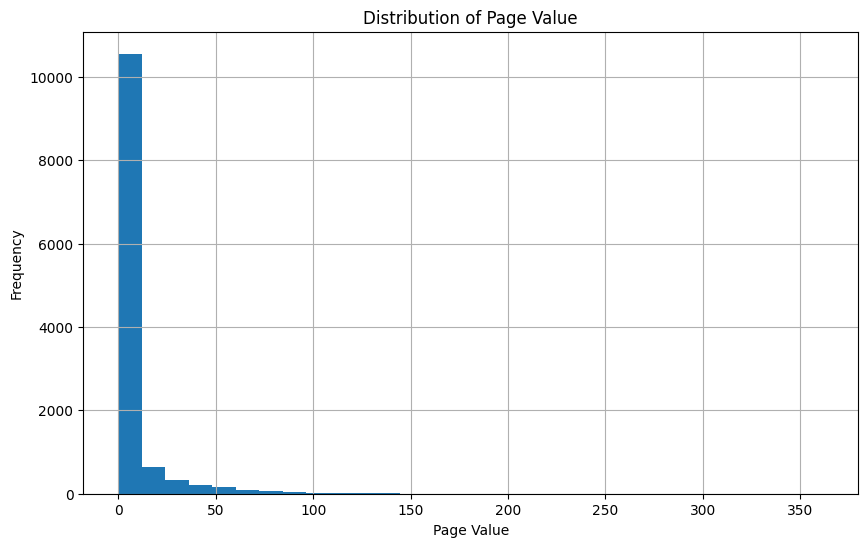

In [34]:
import matplotlib.pyplot as plt
df_clean['page_value'].hist(
    bins=30,
    figsize=(10, 6)
)

plt.title('Distribution of Page Value')
plt.xlabel('Page Value')
plt.ylabel('Frequency')
plt.show()


### Question 39
Create a **bar chart** showing the number of `True` and `False` revenue outcomes.


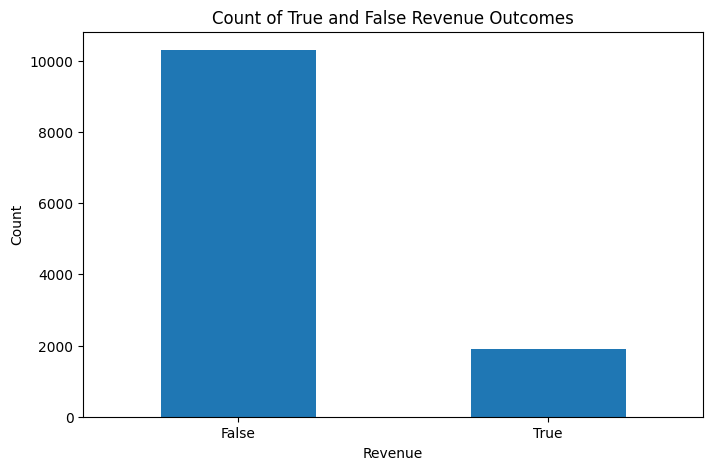

In [35]:
import matplotlib.pyplot as plt

revenue_counts = df_clean['revenue'].value_counts()

revenue_counts.plot(
    kind='bar',
    figsize=(8, 5),
    title='Count of True and False Revenue Outcomes'
)

plt.xlabel('Revenue')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()


### Question 40
Save `df_clean` as **OnlineShoppers_Analyzed.csv** using `to_csv()` without saving the index.


In [36]:
df_clean.to_csv('OnlineShoppers_Analyzed.csv', index=False)

## End of Practice

Try to solve each question independently before checking any reference material.

The main goal is to become comfortable with website-session data, Boolean outcomes, grouped summaries, and simple engagement measures before moving to classification models.
